# GDP Growth Forecasting, Part 5: Baseline Models and Evaluation

**Project:** Forecasting real GDP growth in South Asia

Parts 1–4 (`01_Acquire_Data` … `04_Bivariate_Analysis`) explored the WDI panel. This part builds the forecasting
system and scores the baseline ladder. It answers the three weaknesses raised at the proposal presentation:

| Feedback | What this notebook does |
|---|---|
| **B1.** Imputation can leak information not available at the forecast date | A vintage-aware feature store. No income-group median fill; values carried forward only inside a series' publication lag; remaining gaps filled *inside each training fold* with a missing flag. Real-time (as-published) values of last year's growth replace revised WDI values. |
| **B2.** IMF / World Bank comparison ignores country reporting periods | Step 1 checks the year labels of WEO, GEP and WDI country by country, and computes each country's *effective horizon* (months left in its reporting year at the cutoff). Monthly data are also aggregated over each country's own fiscal year. |
| **B3.** Experiments too broad, no prioritised reproducible baseline | One fixed baseline ladder, one evaluation protocol, one command (`python run_experiments.py`) that regenerates every table and figure. Extensions are ranked P1–P3 in the progress report. |

### Workflow

```
 raw files ──► 1. reconcile reporting periods ──► 2. feature store at cutoff (month m, horizon h)
                                                             │
               3. model ladder (naive → AR → FE → ridge → GBM, + WEO benchmark)
                                                             │
               4. rolling-origin loop: for each year t, refit on outcomes known at the cutoff, predict t+h
                                                             │
    5. scores & paired tests ◄─┬─► 6. feature ablation ─┬─► 7. conformal intervals ─► 8. monthly refresh
```

All code lives in the `prism/` package next to this notebook. The notebook only calls it, so the
command-line runner and the notebook cannot disagree.

> **Runtime.** The first full run builds 15 feature stores and takes about 20 minutes. Results are cached in
> `outputs/cache/`; later runs take seconds. Delete that folder (or run `python run_experiments.py --fresh`) to rebuild.

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import pandas as pd
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

from prism import config as C, data as D, features as F, models as M
from prism import evaluate as E, reconcile as R, experiments as X

try:
    from IPython.display import Image
except ImportError:               # lets the notebook run as a plain script too
    Image = lambda filename: Path(filename)

GBM = 'LightGBM' if M.HAS_LGB else 'GBM (HistGB)'
print('WDI folder :', C.WDI_DIR)
print('Raw folder :', C.RAW_DIR)
print('Gradient boosting backend:', GBM)

WDI folder : /home/claude/Meesha/wdi-dataset/wdi
Raw folder : /home/claude/Meesha/raw-datafiles/raw
Gradient boosting backend: GBM (HistGB)


**About the gradient-boosting backend.** The proposed model is LightGBM. `models.GBM` uses LightGBM whenever
it is installed (`pip install lightgbm`). If it is not, it falls back to scikit-learn's
`HistGradientBoostingRegressor`, which uses the same histogram-based boosting and handles missing values
natively. The results saved in this notebook were produced with the fallback; the LightGBM run is a Week-5 task.
At this stage the GBM is a **preview** with untuned, conservative settings; the point of Part 5 is the baselines.

## 1. Reconcile reporting periods (feedback B2)

South Asian countries do not all report on the calendar year:

| Country | Reporting year | WDI year *t* means |
|---|---|---|
| India | April–March | FY *t*/*t*+1 |
| Bangladesh, Bhutan, Pakistan | July–June | FY *t*−1/*t* |
| Nepal | mid-July–mid-July | FY *t*−1/*t* |
| Sri Lanka, Maldives, Afghanistan | calendar (Afghanistan: solar year) | calendar *t* |

Two things can go wrong. First, two sources may put the same fiscal year under different labels.
Second, even with matching labels, an April forecast of "year *t*" is a very different task for each country.

**Label check.** We take the IMF's own history of each year (the value printed two WEO rounds later, once the
year is over) and compare it with WDI year *t*−1, *t* and *t*+1. The shift with the smallest gap is the label match.

In [2]:
align = R.label_alignment()
align[['country', 'fiscal_year', 'MAE_shift_-1', 'MAE_shift_+0', 'MAE_shift_+1', 'best_shift']].round(2)

,country,fiscal_year,MAE_shift_-1,MAE_shift_+0,MAE_shift_+1,best_shift
0,Afghanistan,"solar year, close to calendar since 2012",7.36,3.80,7.62,0
1,Bangladesh,July-June,0.94,0.47,0.74,0
2,Bhutan,July-June,3.57,1.96,3.35,0
3,India,"April-March, year t = FY t/t+1",2.05,0.92,2.44,0
4,Sri Lanka,calendar year,1.75,0.65,2.15,0
5,Maldives,calendar year,5.97,2.64,8.93,0
6,Nepal,mid-July to mid-July,2.37,0.90,2.22,0
7,Pakistan,July-June,1.45,0.83,1.48,0


Every country matches at shift 0, with a gap 1.6 to 2.7 times smaller than at ±1. **WEO and WDI use the same year
labels**, so the IMF comparison is like-for-like on labels. The gap at shift 0 is not zero, though: it is the
**revision gap** between what the IMF printed and what WDI shows today (about 0.5 pp for Bangladesh, 0.9 pp for India,
2.6 pp for Maldives). That is direct evidence that the choice of "truth" vintage matters (see Step 5c).

The GEP file holds only the June 2026 vintage. Its 2023–2024 columns are already history, so we run the same check:

In [3]:
R.gep_alignment().round(2)

,iso,gap_shift_-1,years_shift_-1,gap_shift_+0,years_shift_+0,gap_shift_+1,years_shift_+1
0,AFG,4.45,"2024,2023",0.03,2023,NaN,
1,BGD,1.44,"2024,2023",0.02,"2024,2023",1.58,2023
2,BTN,0.89,"2024,2023",0.27,2023,NaN,
3,IND,1.25,"2024,2023",1.30,"2024,2023",0.71,2023
4,LKA,6.34,"2024,2023",0.17,"2024,2023",7.01,2023
5,MDV,5.18,"2024,2023",0.02,"2024,2023",1.41,2023
6,NPL,2.67,"2024,2023",0.03,"2024,2023",1.67,2023
7,PAK,4.00,"2024,2023",0.33,"2024,2023",3.25,2023


GEP matches WDI at shift 0 for seven countries (gaps of 0.02–0.33 pp). **India is ambiguous**: shift 0 and shift +1
give similar gaps, most likely because India rebased its national accounts in 2026, so GEP and the older WDI
snapshot are on different base years. This is flagged as an open item. It matters only for the forward-looking
2026–27 comparison, because **the file has no historical GEP vintages, so the World Bank cannot be scored
historically yet** (see the progress report, challenges).

**Effective horizon.** At an end-April cutoff, how many months of each country's target year are still ahead?

In [4]:
R.effective_horizons(4)

,iso,country,reporting_year_2020,months_ahead_h0,months_ahead_h1
0,AFG,Afghanistan,2020-01 to 2020-12,8,20
1,BGD,Bangladesh,2019-07 to 2020-06,2,14
2,BTN,Bhutan,2019-07 to 2020-06,2,14
3,IND,India,2020-04 to 2021-03,11,23
4,LKA,Sri Lanka,2020-01 to 2020-12,8,20
5,MDV,Maldives,2020-01 to 2020-12,8,20
6,NPL,Nepal,2019-08 to 2020-07,3,15
7,PAK,Pakistan,2019-07 to 2020-06,2,14


At the April WEO round, a "current-year" forecast is a near-nowcast for Pakistan, Bangladesh, Bhutan and Nepal
(2–3 months left), an 8-month-ahead forecast for Sri Lanka, Maldives and Afghanistan, and an 11-month-ahead forecast
for India. Pooling them as one "h = 0" hides this, so Step 5d reports errors by effective horizon. The feature
store also adds **fiscal-year-to-date** monthly features that average only the months of the target reporting year.

## 2. The vintage-aware feature store (feedback B1)

`features.build_store(cutoff_month, horizon)` returns one row per (country, origin year *t*). Each row holds
only what was public at the end of month *m* of year *t*, and the realised growth of year *t*+*h*.

| Block | Source | Rule at cutoff (year *t*, month *m*) |
|---|---|---|
| Growth history | WEO vintages | Real-time growth of *t*−1 and *t*−2 **as printed in the latest WEO round** (Oct *t*−1, Apr *t* or Oct *t*). Falls back to WDI only where WEO has no number. |
| Annual structure | WDI | Year *t*−1 values only from July (the WDI release); before that, *t*−2. Carried forward within the country for at most 2 years. |
| Monthly country signals | GEM | 3-month average, year-on-year, up to the last month published (lags of 0–2 months by series). Plus fiscal-year-to-date growth of IP, exports and imports for the target year. |
| Global shocks | Pink Sheet | 3-month y/y change in energy, non-energy, food and metals indices, lag 1 month. |
| Global cycle | WDI | Median growth of all countries in the last known year. |

**What changed from Part 2.** Part 2 filled gaps with a 2-year forward fill and then the **median of the same
income group**. That median is taken across countries *in the same year*, including years after the forecast date,
and it is computed on the whole sample. Here there is no cross-sectional fill. Remaining gaps stay `NaN`; the linear
models fill them with the median **of the training fold only**, plus a 0/1 missing flag. The tree model takes `NaN` directly.

In [5]:
store = E.load_store(4, 0)
groups = F.feature_groups(store)
print(store.shape)
{k: len(v) for k, v in groups.items()}

(13293, 62)


{'growth': 5, 'annual': 27, 'monthly': 11, 'pink': 4, 'growth_revised': 5}

In [6]:
# What a forecaster knew about Sri Lanka at end-April of each year
cols = ['iso', 'year', 'target_year', 'y', 'g_lag1', 'g_lag1_rt', 'exports_m_fytd', 'pink_energy_yoy3', 'remittances_a', 'months_ahead']
store.query("iso == 'LKA' and 2018 <= year <= 2023")[cols].round(2)

,iso,year,target_year,y,g_lag1,g_lag1_rt,exports_m_fytd,pink_energy_yoy3,remittances_a,months_ahead
6986,LKA,2018,2018,2.31,6.46,3.11,8.44,22.34,8.25,8
6987,LKA,2019,2019,-0.22,2.31,3.02,7.75,-5.48,7.62,8
6988,LKA,2020,2020,-4.62,-0.22,2.28,-0.88,-22.43,7.46,8
6989,LKA,2021,2021,4.21,-4.62,-3.57,-5.08,24.87,7.58,8
6990,LKA,2022,2022,-7.35,4.21,3.58,16.42,82.38,8.47,8
6991,LKA,2023,2023,-2.33,-7.35,-7.35,-10.41,-20.90,6.24,8


`g_lag1` is last year's growth as WDI shows it **today**; `g_lag1_rt` is the number the IMF printed in April of that
year. For Sri Lanka in April 2019, the 2018 figure was 3.0% in real time but 2.3% after revision. A model trained
on `g_lag1` learns from numbers nobody had. (From 2023 the WEO file ends, so `g_lag1_rt` falls back to WDI.)

How much of the South Asian feature matrix is missing under the new rules (rows used for evaluation, 2000–2024)?

In [7]:
sa = store[(store.is_sa == 1) & store.year.between(2000, 2024)]
miss = sa[groups['annual'] + groups['monthly']].isna().mean().sort_values(ascending=False)
miss.head(12).round(2).to_frame('share missing')

,share missing
reer_m_yoy3,0.75
ip_fytd,0.69
ip_yoy3,0.57
imports_m_fytd,0.54
exports_m_fytd,0.48
impcov_m_lvl3,0.44
imports_m_yoy3,0.42
exports_m_yoy3,0.36
energy_use_a,0.32
reserves_m_yoy3,0.24


Industrial production, the REER and the monthly trade series are missing for several South Asian economies (GEM
does not cover Afghanistan, Bhutan or Nepal for most of them). Under Part 2's method these cells would have been
filled with the income-group median; here they stay empty and the model is told they are empty.

## 3. The model ladder

| # | Model | What it uses | Why it is on the ladder |
|---|---|---|---|
| 1 | **Naive (real-time)** | last year's growth as printed at the time | the reference: all skill is measured against it |
| 1b | Naive (revised data) | last year's growth as revised later | shows the cost of using revised data |
| 2 | Country mean | the country's own past average | the "long-run trend" forecast |
| 3 | **AR(2) pooled** | two real-time growth lags, one coefficient set for all countries | the standard time-series baseline |
| 4 | AR(2) + country FE | same, each country reverts to its own mean | proposal's fixed-effects baseline |
| 5 | Ridge + FE (annual only) | growth lags + annual WDI + country dummies | regularised linear FE, annual data only |
| 6 | Ridge + country FE | all features + country dummies | adds monthly and global data |
| 7 | **Ridge pooled** | all features, income and region dummies | regularised linear without country dummies |
| 8 | **GBM** (preview) | all features, NaN kept | the proposed model family |
| B | **IMF WEO** | WEO forecast from the latest round at the cutoff | the institutional benchmark (held out, never a feature except in 9) |
| 9 | WEO + ridge correction | WEO plus a ridge model of WEO's past error | the proposal's stacked correction |

**A correction to the proposal.** The proposal listed *country and year* fixed effects. Year effects cannot be used
to forecast: the effect of a future year is unknown at the forecast date. They are replaced with observed common
factors (world growth, commodity prices), which a forecaster does have.

Linear models and the GBM are trained on the target clipped at the training fold's 1st/99th percentiles (the
winsorising from Part 3). Scores always use the **unclipped** realised value.

In [8]:
[m.name for m in X.model_ladder(store)]

['Naive (real-time)', 'Naive (revised data)', 'Country mean', 'AR(2) pooled', 'AR(2) + country FE', 'Ridge + FE (annual only)', 'Ridge + country FE', 'Ridge pooled', 'GBM (HistGB)', 'IMF WEO', 'WEO + ridge correction']

## 4. Rolling-origin evaluation

For every origin year *t* from 2000 to 2024:

1. **Train** on every country-year (all 208 economies, South Asia's own past included) whose outcome was public at
   the cutoff: target year ≤ *t*−1, origin year ≥ 1992 (the start of the monthly data).
2. **Refit** every model from scratch on that training set.
3. **Predict** year *t*+*h* for every country.

The window expands by one year at each step. Nothing from year *t* or later reaches the model.
South Asia is the evaluation set; the rest of the world is also scored, as a check.

The IMF benchmark exists for target years up to 2022 (the last vintage in `WEOhistorical.xlsx` is October 2022),
so the head-to-head window is **2000–2022**: 181 South Asian country-years at *h* = 0 and 174 at *h* = 1.

In [9]:
preds = {tag: X.run_ladder(m, h) for tag, (m, h) in
         {'m04_h0': (4, 0), 'm04_h1': (4, 1), 'm06_h0': (6, 0), 'm06_h1': (6, 1)}.items()}
p = preds['m04_h0']
print(p.shape)
p.head()

(55418, 11)


,model,iso,origin,target_year,y,pred,is_sa,months_ahead,cutoff_month,horizon,n_train
0,Naive (real-time),ABW,2000,2000,7.62292,1.238040,0,8,4,0,1556
1,Naive (real-time),AGO,2000,2000,3.05462,1.283994,0,8,4,0,1556
2,Naive (real-time),ALB,2000,2000,7.46286,8.000001,0,8,4,0,1556
3,Naive (real-time),AND,2000,2000,3.52836,4.099080,0,8,4,0,1556
4,Naive (real-time),ARE,2000,2000,10.85270,8.503906,0,8,4,0,1556


## 5. Results

### 5a. April cutoff, current year (*h* = 0), South Asia, 2000–2022
All models are scored on the same country-years. `RMSE_vs_naive` below 1 means better than the naive forecast.
MAPE is computed only where |growth| > 1 pp, because it explodes near zero growth.

In [10]:
E.score_table(p, years=X.WEO_WINDOW).round(2)

,n,RMSE,MAE,MAPE_%,R2,RMSE_vs_naive
model,,,,,,
IMF WEO,181,4.86,2.71,43.86,0.38,0.59
WEO + ridge correction,181,5.26,2.91,46.67,0.28,0.64
GBM (HistGB),181,6.35,3.41,53.51,-0.05,0.77
Ridge pooled,181,6.46,3.43,53.72,-0.09,0.78
AR(2) pooled,181,6.51,3.60,53.18,-0.11,0.79
Ridge + country FE,181,6.52,3.86,64.64,-0.11,0.79
Country mean,181,6.71,3.49,62.03,-0.18,0.81
Ridge + FE (annual only),181,6.73,4.09,69.32,-0.18,0.82
AR(2) + country FE,181,6.76,3.47,58.87,-0.19,0.82


In [11]:
E.score_table(p, years=X.WEO_WINDOW, exclude_crisis=True).round(2)

,n,RMSE,MAE,MAPE_%,R2,RMSE_vs_naive
model,,,,,,
IMF WEO,165,3.78,2.26,40.70,0.23,0.71
WEO + ridge correction,165,4.12,2.43,42.83,0.09,0.77
GBM (HistGB),165,4.50,2.69,45.49,-0.09,0.85
AR(2) pooled,165,4.50,2.87,44.95,-0.09,0.85
Ridge pooled,165,4.52,2.67,45.13,-0.10,0.85
Ridge + country FE,165,4.54,3.12,57.46,-0.11,0.85
Ridge + FE (annual only),165,4.83,3.34,61.31,-0.25,0.91
AR(2) + country FE,165,4.85,2.72,50.64,-0.26,0.91
Country mean,165,4.99,2.79,54.17,-0.34,0.94


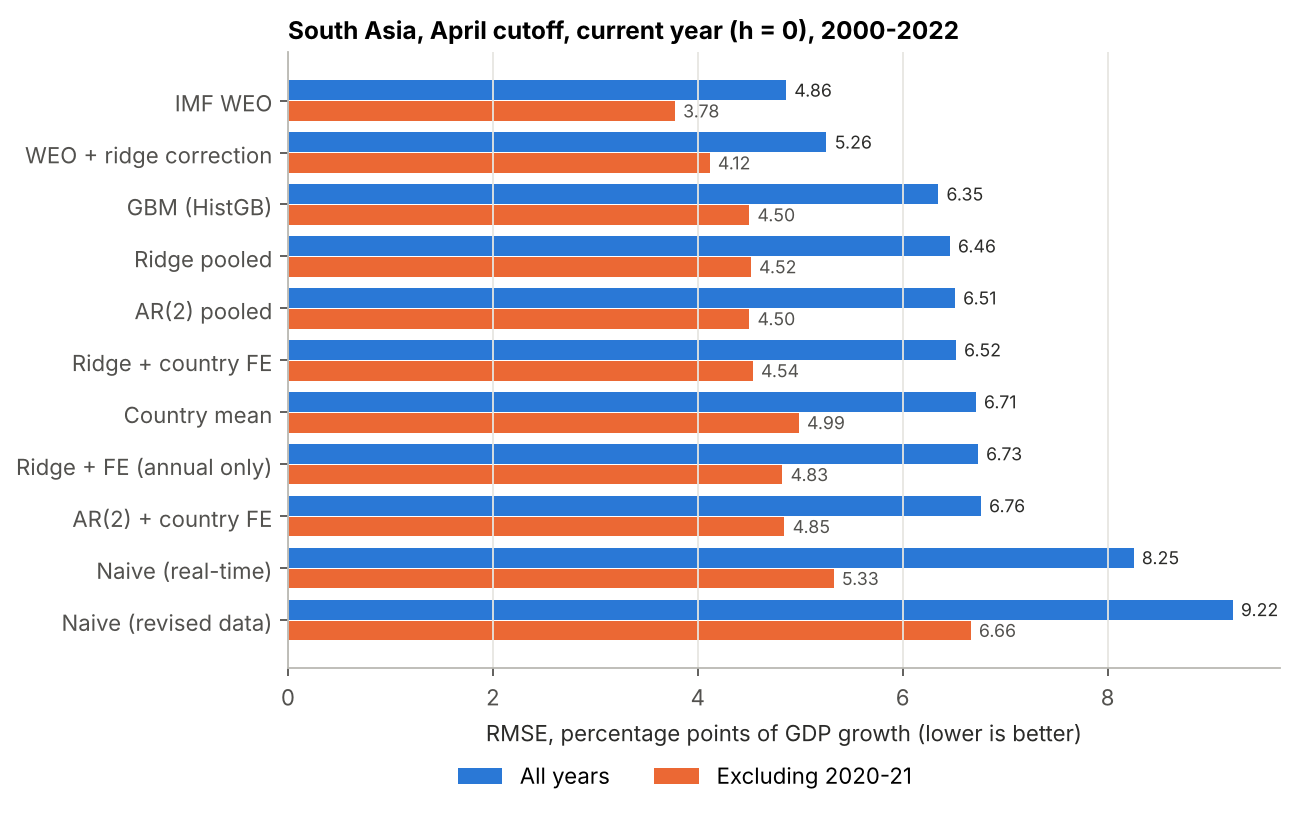

In [12]:
Image(filename=str(C.FIG_DIR / 'fig1_baseline_ladder.png'))

### 5b. April cutoff, next year (*h* = 1)

In [13]:
E.score_table(preds['m04_h1'], years=X.WEO_WINDOW).round(2)

,n,RMSE,MAE,MAPE_%,R2,RMSE_vs_naive
model,,,,,,
IMF WEO,174,5.73,3.29,59.62,0.12,0.77
WEO + ridge correction,174,6.03,3.44,57.06,0.03,0.81
AR(2) pooled,174,6.16,3.62,54.50,-0.01,0.82
GBM (HistGB),174,6.17,3.51,60.12,-0.02,0.83
Ridge pooled,174,6.23,3.51,58.84,-0.04,0.83
AR(2) + country FE,174,6.33,3.50,62.22,-0.07,0.85
Country mean,174,6.40,3.54,65.55,-0.09,0.86
Ridge + country FE,174,6.60,3.91,71.95,-0.16,0.88
Ridge + FE (annual only),174,6.80,4.09,78.61,-0.24,0.91


In [14]:
E.score_table(preds['m04_h1'], years=X.WEO_WINDOW, exclude_crisis=True).round(2)

,n,RMSE,MAE,MAPE_%,R2,RMSE_vs_naive
model,,,,,,
IMF WEO,158,3.83,2.61,52.26,0.13,0.63
WEO + ridge correction,158,4.23,2.77,49.51,-0.06,0.70
AR(2) pooled,158,4.33,2.98,47.31,-0.11,0.71
Ridge pooled,158,4.34,2.83,51.36,-0.11,0.71
GBM (HistGB),158,4.35,2.87,53.38,-0.12,0.72
AR(2) + country FE,158,4.40,2.79,54.25,-0.14,0.72
Country mean,158,4.45,2.81,57.60,-0.17,0.73
Ridge + country FE,158,4.86,3.25,66.25,-0.39,0.80
Ridge + FE (annual only),158,5.15,3.45,73.35,-0.57,0.85


### 5c. Paired tests against the IMF and against the naive forecast
Diebold–Mariano test on squared errors with the Harvey–Leybourne–Newbold correction, pooled over South Asian
country-years. A positive `mean_loss_diff` means the model is *worse* than the benchmark.

In [15]:
dm0 = pd.read_csv(C.TAB_DIR / 'm04_h0_dm_tests.csv', index_col=0)
dm1 = pd.read_csv(C.TAB_DIR / 'm04_h1_dm_tests.csv', index_col=0)
pd.concat({'h=0': dm0[dm0.bench == 'IMF WEO'].set_index('model'),
           'h=1': dm1[dm1.bench == 'IMF WEO'].set_index('model')}, axis=1)[
    [('h=0', 'mean_loss_diff'), ('h=0', 'p_value'), ('h=1', 'mean_loss_diff'), ('h=1', 'p_value')]].round(3)

h=0                    h=1        
                         mean_loss_diff p_value mean_loss_diff p_value
model                                                                 
Naive (real-time)                44.248   0.086         22.586   0.074
Naive (revised data)             61.384   0.026         37.052   0.009
Country mean                     20.948   0.013          8.197   0.016
AR(2) pooled                     18.401   0.053          5.131   0.165
AR(2) + country FE               21.589   0.025          7.418   0.028
Ridge + FE (annual only)         24.520   0.012         31.622   0.075
Ridge + country FE               20.472   0.032         26.684   0.084
Ridge pooled                     17.618   0.056          6.135   0.083
GBM (HistGB)                     16.536   0.034          5.149   0.140
WEO + ridge correction            3.437   0.101          4.565   0.157

**Which truth?** Scored against the IMF's first published estimate (a year later) instead of today's WDI value:

In [16]:
pd.read_csv(C.TAB_DIR / 'm04_h0_scores_vs_first_release.csv', index_col=0)

,n,RMSE,MAE,MAPE_%,R2,RMSE_vs_naive
model,,,,,,
IMF WEO,173,3.080,1.566,25.561,0.629,0.427
WEO + ridge correction,173,3.609,1.858,31.354,0.490,0.500
GBM (HistGB),173,5.145,2.609,40.977,-0.036,0.712
Country mean,173,5.276,2.770,52.747,-0.090,0.730
Ridge pooled,173,5.311,2.651,42.521,-0.104,0.735
AR(2) pooled,173,5.396,2.774,41.748,-0.140,0.747
AR(2) + country FE,173,5.410,2.683,47.587,-0.146,0.749
Ridge + country FE,173,5.822,3.321,56.170,-0.327,0.806
Ridge + FE (annual only),173,5.971,3.513,60.838,-0.396,0.827


### 5d. Where the errors are: by country and by effective horizon

In [17]:
pd.read_csv(C.TAB_DIR / 'm04_h0_rmse_by_country.csv', index_col=0)

,AR(2) pooled,GBM (HistGB),IMF WEO,Naive (real-time),n
Afghanistan,9.36,9.54,9.12,9.20,21
Bangladesh,1.87,1.07,0.69,1.31,23
Bhutan,4.69,4.78,4.24,6.03,23
India,3.71,3.71,2.57,4.84,23
Sri Lanka,3.62,3.78,3.01,4.01,23
Maldives,14.06,13.43,8.94,19.32,23
Nepal,2.71,2.75,1.90,3.58,23
Pakistan,2.11,2.04,1.68,2.35,23


In [18]:
pd.read_csv(C.TAB_DIR / 'm04_h0_rmse_by_effective_horizon.csv', index_col=0)

,GBM (HistGB),IMF WEO,Naive (real-time),n,countries
horizon_group,,,,,
0-4 mo,2.99,2.49,3.76,92,"BGD, BTN, NPL, PAK"
5-9 mo,9.76,7.52,12.66,67,"AFG, LKA, MDV"
10-13 mo,3.71,2.57,4.84,23,IND


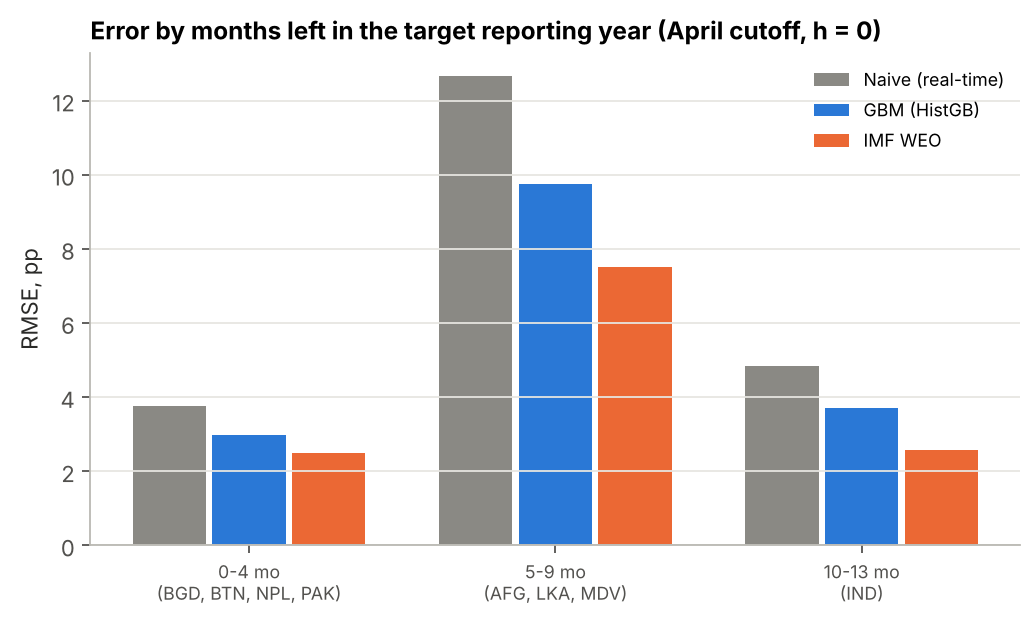

In [19]:
Image(filename=str(C.FIG_DIR / 'fig5_effective_horizon.png'))

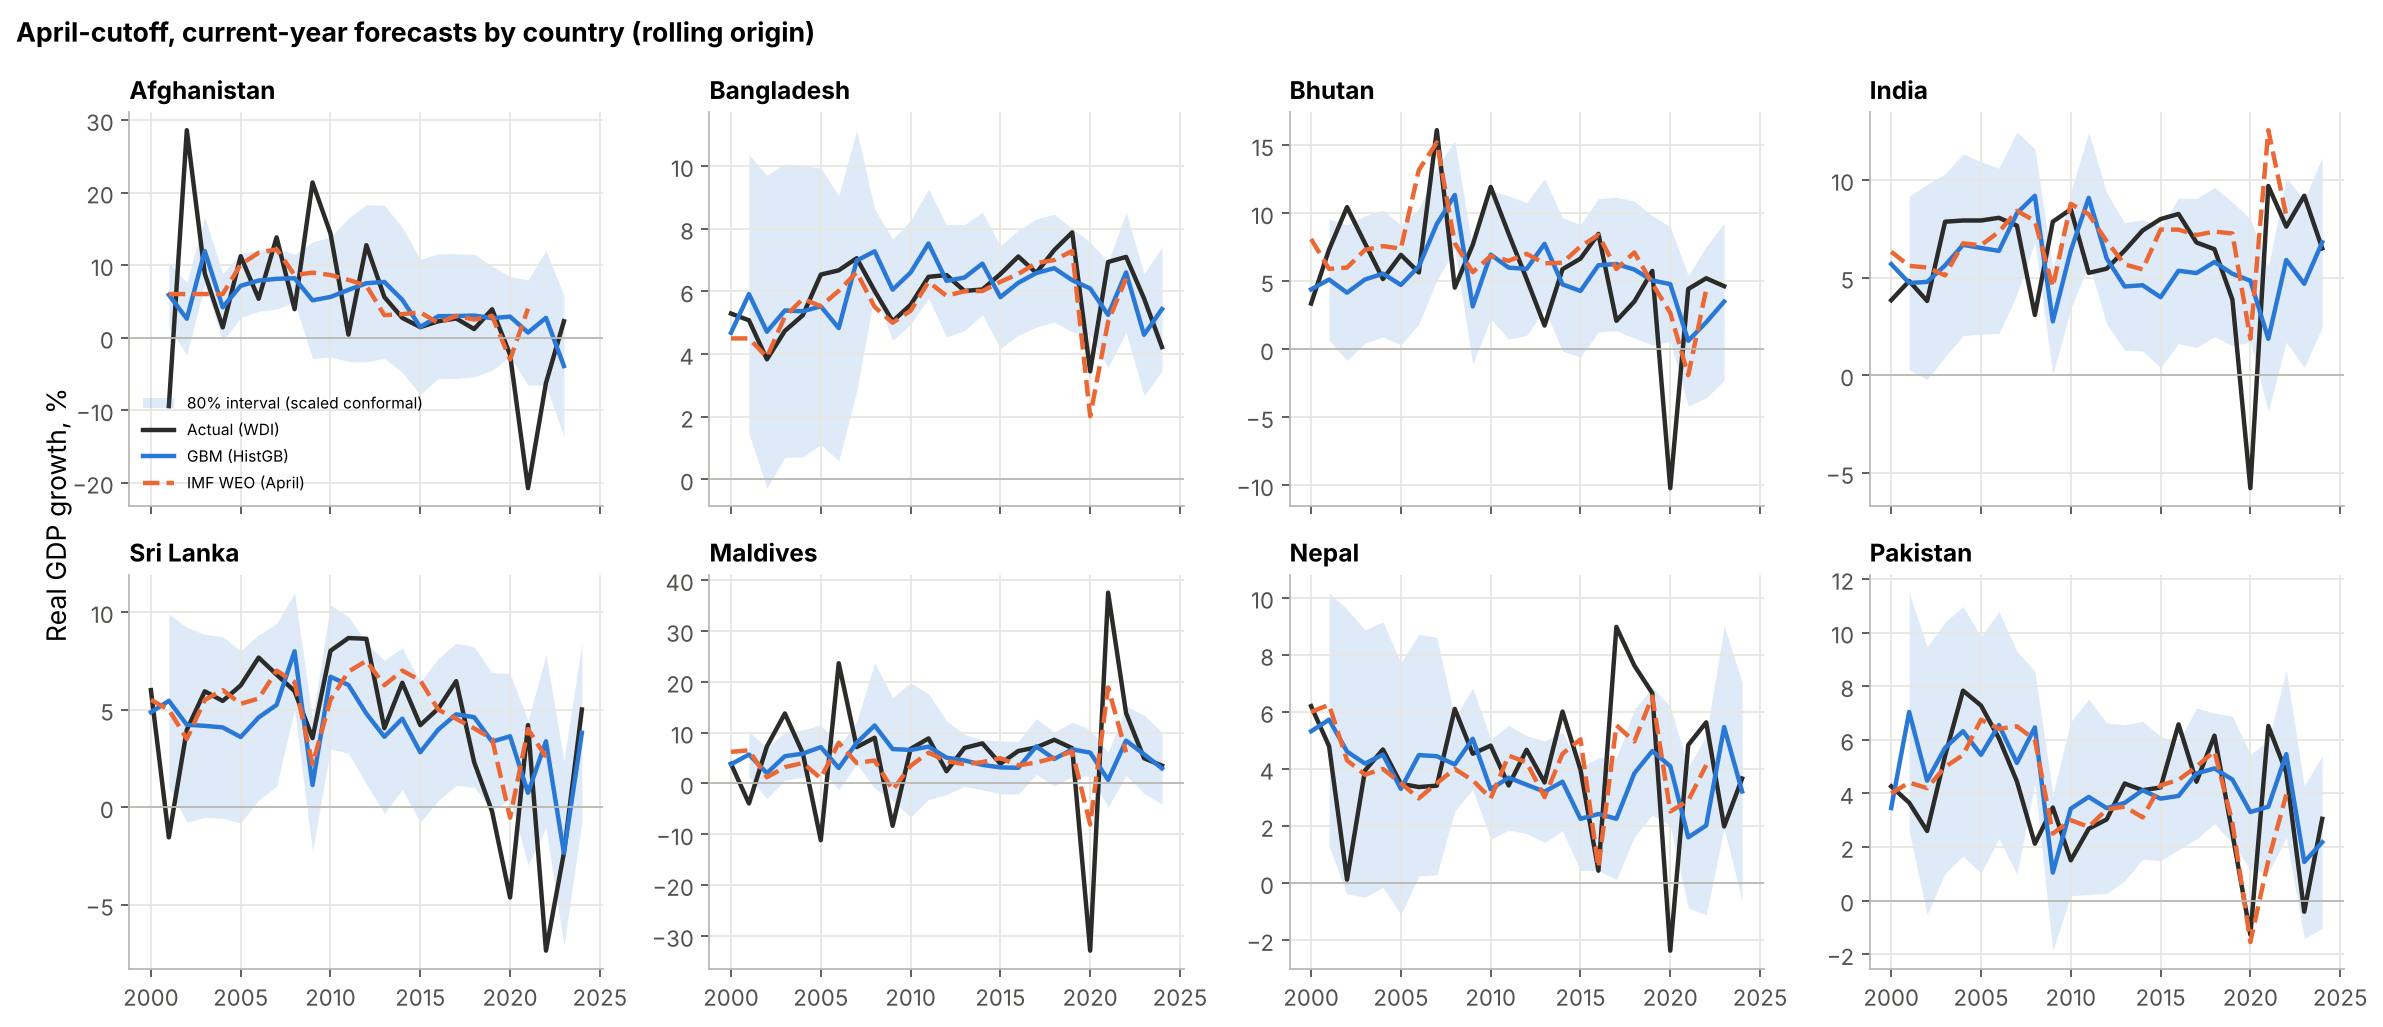

In [20]:
Image(filename=str(C.FIG_DIR / 'fig3_country_forecasts.png'))

### 5e. June cutoff (the GEP round)
The World Bank cannot be scored historically with the files we have, so at June the benchmark is still the April WEO
(the latest IMF round public in June). Our models gain two more months of monthly data.

In [21]:
E.score_table(preds['m06_h0'], years=X.WEO_WINDOW).round(2)

,n,RMSE,MAE,MAPE_%,R2,RMSE_vs_naive
model,,,,,,
IMF WEO,181,4.86,2.71,43.86,0.38,0.59
WEO + ridge correction,181,5.28,2.96,47.20,0.27,0.64
GBM (HistGB),181,6.15,3.26,51.88,0.01,0.75
Ridge pooled,181,6.30,3.35,51.65,-0.04,0.76
Ridge + country FE,181,6.40,3.77,62.25,-0.07,0.77
AR(2) pooled,181,6.51,3.60,53.18,-0.11,0.79
Country mean,181,6.71,3.49,62.03,-0.18,0.81
Ridge + FE (annual only),181,6.73,4.09,69.32,-0.18,0.82
AR(2) + country FE,181,6.76,3.47,58.87,-0.19,0.82


## 6. Feature ablation: does mixed-frequency data help? (towards research question 1)
Ridge pooled and the GBM refit with growing feature sets, April cutoff, *h* = 0, test years 2000–2024. The last row
swaps the real-time growth lags for revised WDI values, to measure the vintage effect.

In [22]:
X.ablation(4, 0)

sample                            Rest of world        South Asia       
family                                      GBM  Ridge        GBM  Ridge
features                                                                
growth history only                       5.851  5.900      6.363  6.354
+ annual WDI                              5.744  5.947      6.292  6.358
+ annual + monthly GEM                    5.647  5.830      6.239  6.327
+ annual + monthly + Pink Sheet           5.672  5.798      6.247  6.300
all features, REVISED growth lags         5.605  5.709      6.377  6.448

## 7. Prediction intervals (towards research question 2)
Split-conformal 80% intervals, built only from earlier out-of-sample residuals (last 10 origins, all countries):

* **global**: one half-width for everyone (the proposal's design);
* **scaled**: residuals divided by each country's own past residual spread, so volatile economies get wider bands;
* **adaptive**: scaled, plus adaptive conformal inference: each country's miscoverage level moves after every
  hit or miss, once that outcome is public.

In [23]:
cov = pd.read_csv(C.TAB_DIR / 'm04_h0_interval_coverage.csv', index_col=0)
cov[cov.model == GBM].pivot(index='sample', columns='method', values=['coverage_%', 'mean_width_pp']).round(1)

coverage_%               mean_width_pp              
method                      adaptive global scaled      adaptive global scaled
sample                                                                        
Rest of world                   77.9   79.1   77.2          10.1    8.7    8.8
South Asia, 2020-21 only        25.0   37.5   18.8           8.2    7.6    7.2
South Asia, all years           77.4   79.0   74.7           9.9    8.7    8.6
South Asia, excl. 2020-21       82.2   82.8   79.9          10.0    8.8    8.8

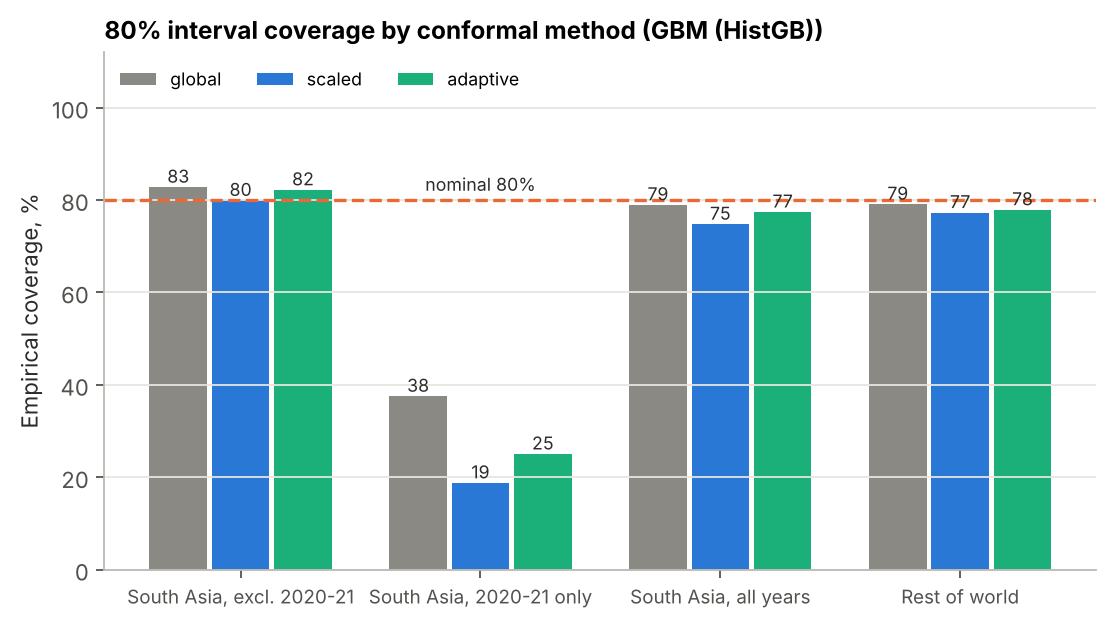

In [24]:
Image(filename=str(C.FIG_DIR / 'fig4_interval_coverage.png'))

## 8. Monthly refresh
The same current-year target re-estimated at every month-end. Each line uses one common sample per month
(South Asia, 2000–2022). The IMF line steps at its April and October rounds; January–March use the previous October round.

In [25]:
pd.read_csv(C.TAB_DIR / 'refresh_h0_rmse_by_cutoff.csv', index_col=0)[
    ['Naive (real-time) [2000-22]', 'AR(2) pooled [2000-22]', 'Ridge pooled [2000-22]', f'{GBM} [2000-22]', 'IMF WEO [2000-22]']]

,Naive (real-time) [2000-22],AR(2) pooled [2000-22],Ridge pooled [2000-22],GBM (HistGB) [2000-22],IMF WEO [2000-22]
1,7.641,6.347,6.358,6.361,5.996
2,7.641,6.347,6.341,6.276,5.996
3,7.468,6.477,6.533,6.508,5.996
4,8.311,6.574,6.514,6.431,4.982
5,8.311,6.574,6.438,6.412,4.982
6,8.311,6.574,6.355,6.226,4.982
7,8.311,6.574,6.157,6.136,4.982
8,8.311,6.574,6.144,6.119,4.982
9,8.311,6.574,6.151,6.048,4.982
10,8.277,6.386,6.052,5.913,3.968


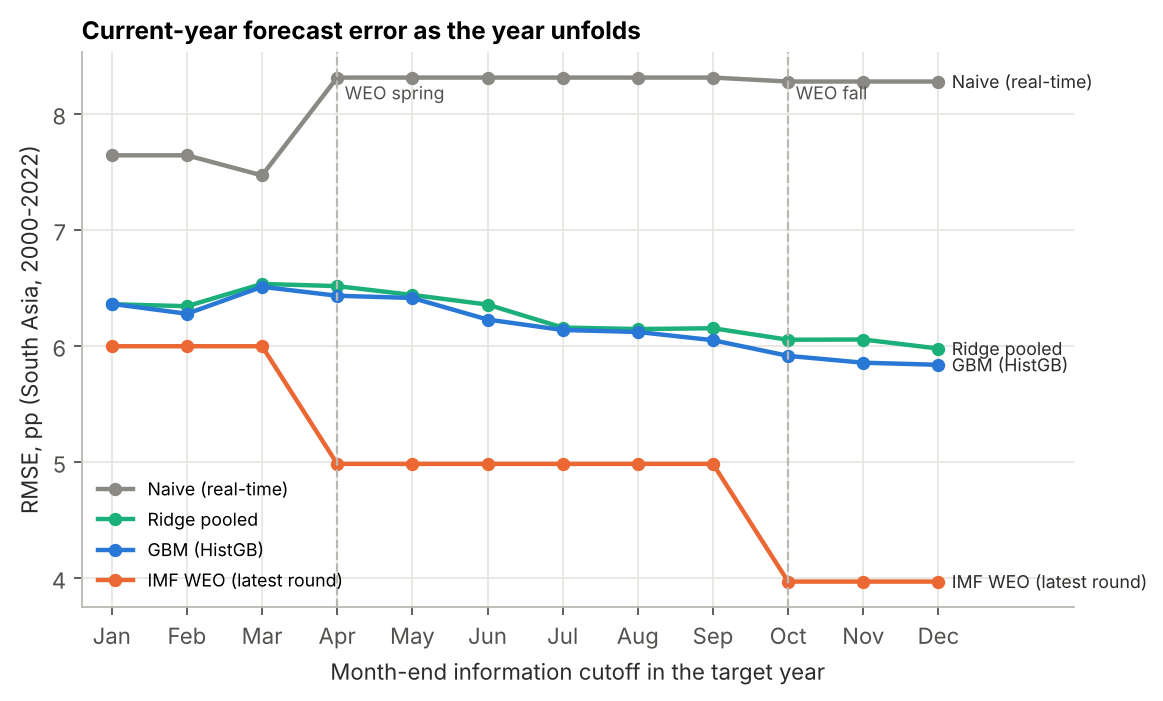

In [26]:
Image(filename=str(C.FIG_DIR / 'fig2_monthly_refresh.png'))

## 9. What the findings suggest

1. **Every model beats the naive forecast, and the IMF beats every model.** At the April cutoff (*h* = 0) the best
   feature model (GBM preview, RMSE 6.35 pp) is 23% better than the real-time naive forecast (8.25), but the WEO is
   better still (4.86). The gap is statistically significant at *h* = 0 (DM p ≈ 0.03 for the GBM), not at *h* = 1
   (p ≈ 0.14), where, once 2020–21 are excluded, the AR(2) and GBM are 13–14% behind the IMF (4.33 and 4.35 vs 3.83).
2. **Simple beats complex among the baselines.** Pooled AR(2) and pooled ridge match or beat the fixed-effects
   versions. Country dummies add noise: 60 years per country are too few to estimate them well. This confirms the
   global-panel design.
3. **Revised data flatter.** The naive forecast built from revised data is 12% worse for South Asia than the real-time
   one at *h* = 0; in the ablation, revised lags look *better* for the rest of the world (5.61 vs 5.67) but *worse*
   for South Asia (6.38 vs 6.25). Revised history is not a free gain, and its look-ahead can mislead evaluation.
4. **Monthly data help, a little, and keep helping through the year.** Adding GEM monthly features lowers GBM RMSE
   from 6.29 to 6.24 (South Asia) and 5.74 to 5.65 (rest of world). Through the year, GBM error falls from 6.43 (April)
   to 5.84 (December). The WEO falls faster, because it uses quarterly national accounts and country desk knowledge we do not have.
5. **The IMF's lead is largest at the long effective horizon.** For India (11 months left at April) the IMF's RMSE is
   2.57 against 3.71; for the July–June reporters (2–3 months left) the gap is smaller (2.49 vs 2.99).
6. **Intervals are calibrated in normal years and fail in crises.** Global conformal intervals cover 83% of South Asian
   outcomes outside 2020–21, but only 38% in 2020–21. Scaling and adaptive updating did not fix the crisis case in this first try.
7. **Maldives and Afghanistan dominate squared error** (RMSE 13.4 and 9.5 for the GBM). Results are always reported with
   and without 2020–21, and per country.

Next steps are in the progress report: switch to LightGBM and tune it (P1), add a quarterly-GDP/nowcast block and
fiscal-year-aware targets (P1), crisis-aware intervals (P2), GEP vintages (P2).